# <a href="https://thetahat.ru/courses/ds-group">Машинное обучение, DS-поток</a>

## Задание ML.2

**Правила:**

* Дедлайны см. студенческом кабинете. После дедлайна работы не принимаются кроме случаев наличия уважительной причины.
* Прислать нужно **ноутбук в формате `ipynb`**.
* Следите за размером файлов. **Сайт не может принимать файлы весом более 50 Мб.** Если файл получается больше, заранее разделите его на несколько.
* Выполнять задание необходимо полностью самостоятельно. **При обнаружении списывания все участники списывания будут сдавать устный зачет.**
* Решения, размещенные на каких-либо интернет-ресурсах, не принимаются. Кроме того, публикация решения в открытом доступе может быть приравнена к предоставлении возможности списать.
* Для выполнения задания используйте этот ноутбук в качестве основы, **не исправляйте и не удаляйте условия!** Можно добавлять необходимое количество ячеек.
* Комментарии к решению пишите в markdown-ячейках.
* Выполнение задания (ход решения, выводы и пр.) должно быть осуществлено на русском языке.
* Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/"><img src="https://miptstats.github.io/theta_grader_small.png" style="display: inline; vertical-align: middle;"></a> **ThetaGrader**. Результат проверки валидируется и исправляется человеком, после чего комментарии отправляются студентам.
* Если код будет не понятен проверяющему, оценка может быть снижена.
* Никакой код из данного задания при проверке запускаться не будет. *Если код студента не выполнен, недописан и т.д., то он не оценивается.*
* В каждой задаче не забывайте делать **пояснения и выводы**.

**Правила оформления теоретических задач:**

* Решения необходимо прислать в виде $\LaTeX$ в markdown-ячейках.
* В решениях поясняйте, чем вы пользуетесь, хотя бы кратко. Например, если пользуетесь независимостью, то достаточно подписи вида "*X и Y незав.*"
* Решение, в котором есть только ответ, и отсутствуют вычисления, оценивается в 0 баллов.

----

**Баллы за задание:**

* Задача 1 &mdash; 20 баллов;
* Задача 2 &mdash; 20 баллов;
* Задача 3 &mdash; 40 баллов;
* Задача 4 &mdash; 120 баллов;

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 3**
1. https://share.google/aimode/osZC5Zs1eTNILLXm2
    - что имеется ввиду под p_k в условии задачи, они не фиксированны, они перебираются?
    - То есть рассматриваются различные варианты предсказанных p_k, так чтобы в сумме все вероятности предсказанные дали = 1, так? и из них надо выбрать наилучшие: \hat{p_1}, ..., \hat{p_k}?
**Задача 4:**
1. https://share.google/aimode/X4pXxqWe9SsJy4FAn
    - У меня y.shape[0] == 0 (это вектор из numpy), тогда np.sum(y) корректно выдаст 0?
    - У меня есть вектор y, [np.sum(Y == k) / Y.shape[0] for k in np.unique(y)] хочу получить частоты классов, в пандас я бы это сделала с помощью value_counts(), а в нампай есть такое?
2. https://share.google/aimode/wlSyTwSlQsbUp4aJA
    - если у меня из уникальных только 1 и 2 класс, а мне то надо и остальные вероятности вплоть до k класса заполнить нулями, тогда как это сделать

In [1]:
# Bot check

# HW_ID: ds_ml2
# Бот проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так бот проверит, что ты отправляешь финальную версию, а не промежуточную.
# Никакие значения в этой ячейке не влияют на факт сдачи работы.

In [2]:
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator
from sklearn.metrics import accuracy_score, r2_score
from sklearn.model_selection import train_test_split
from typing import Optional, Callable

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(font_scale=1.3, palette="Set2")

### Задача 1

Докажите, что индекс Джини равен вероятности ошибки случайного классификатора, который выдаёт предсказания с вероятностями пропорционально доле классов в выборке.

**Решение:**

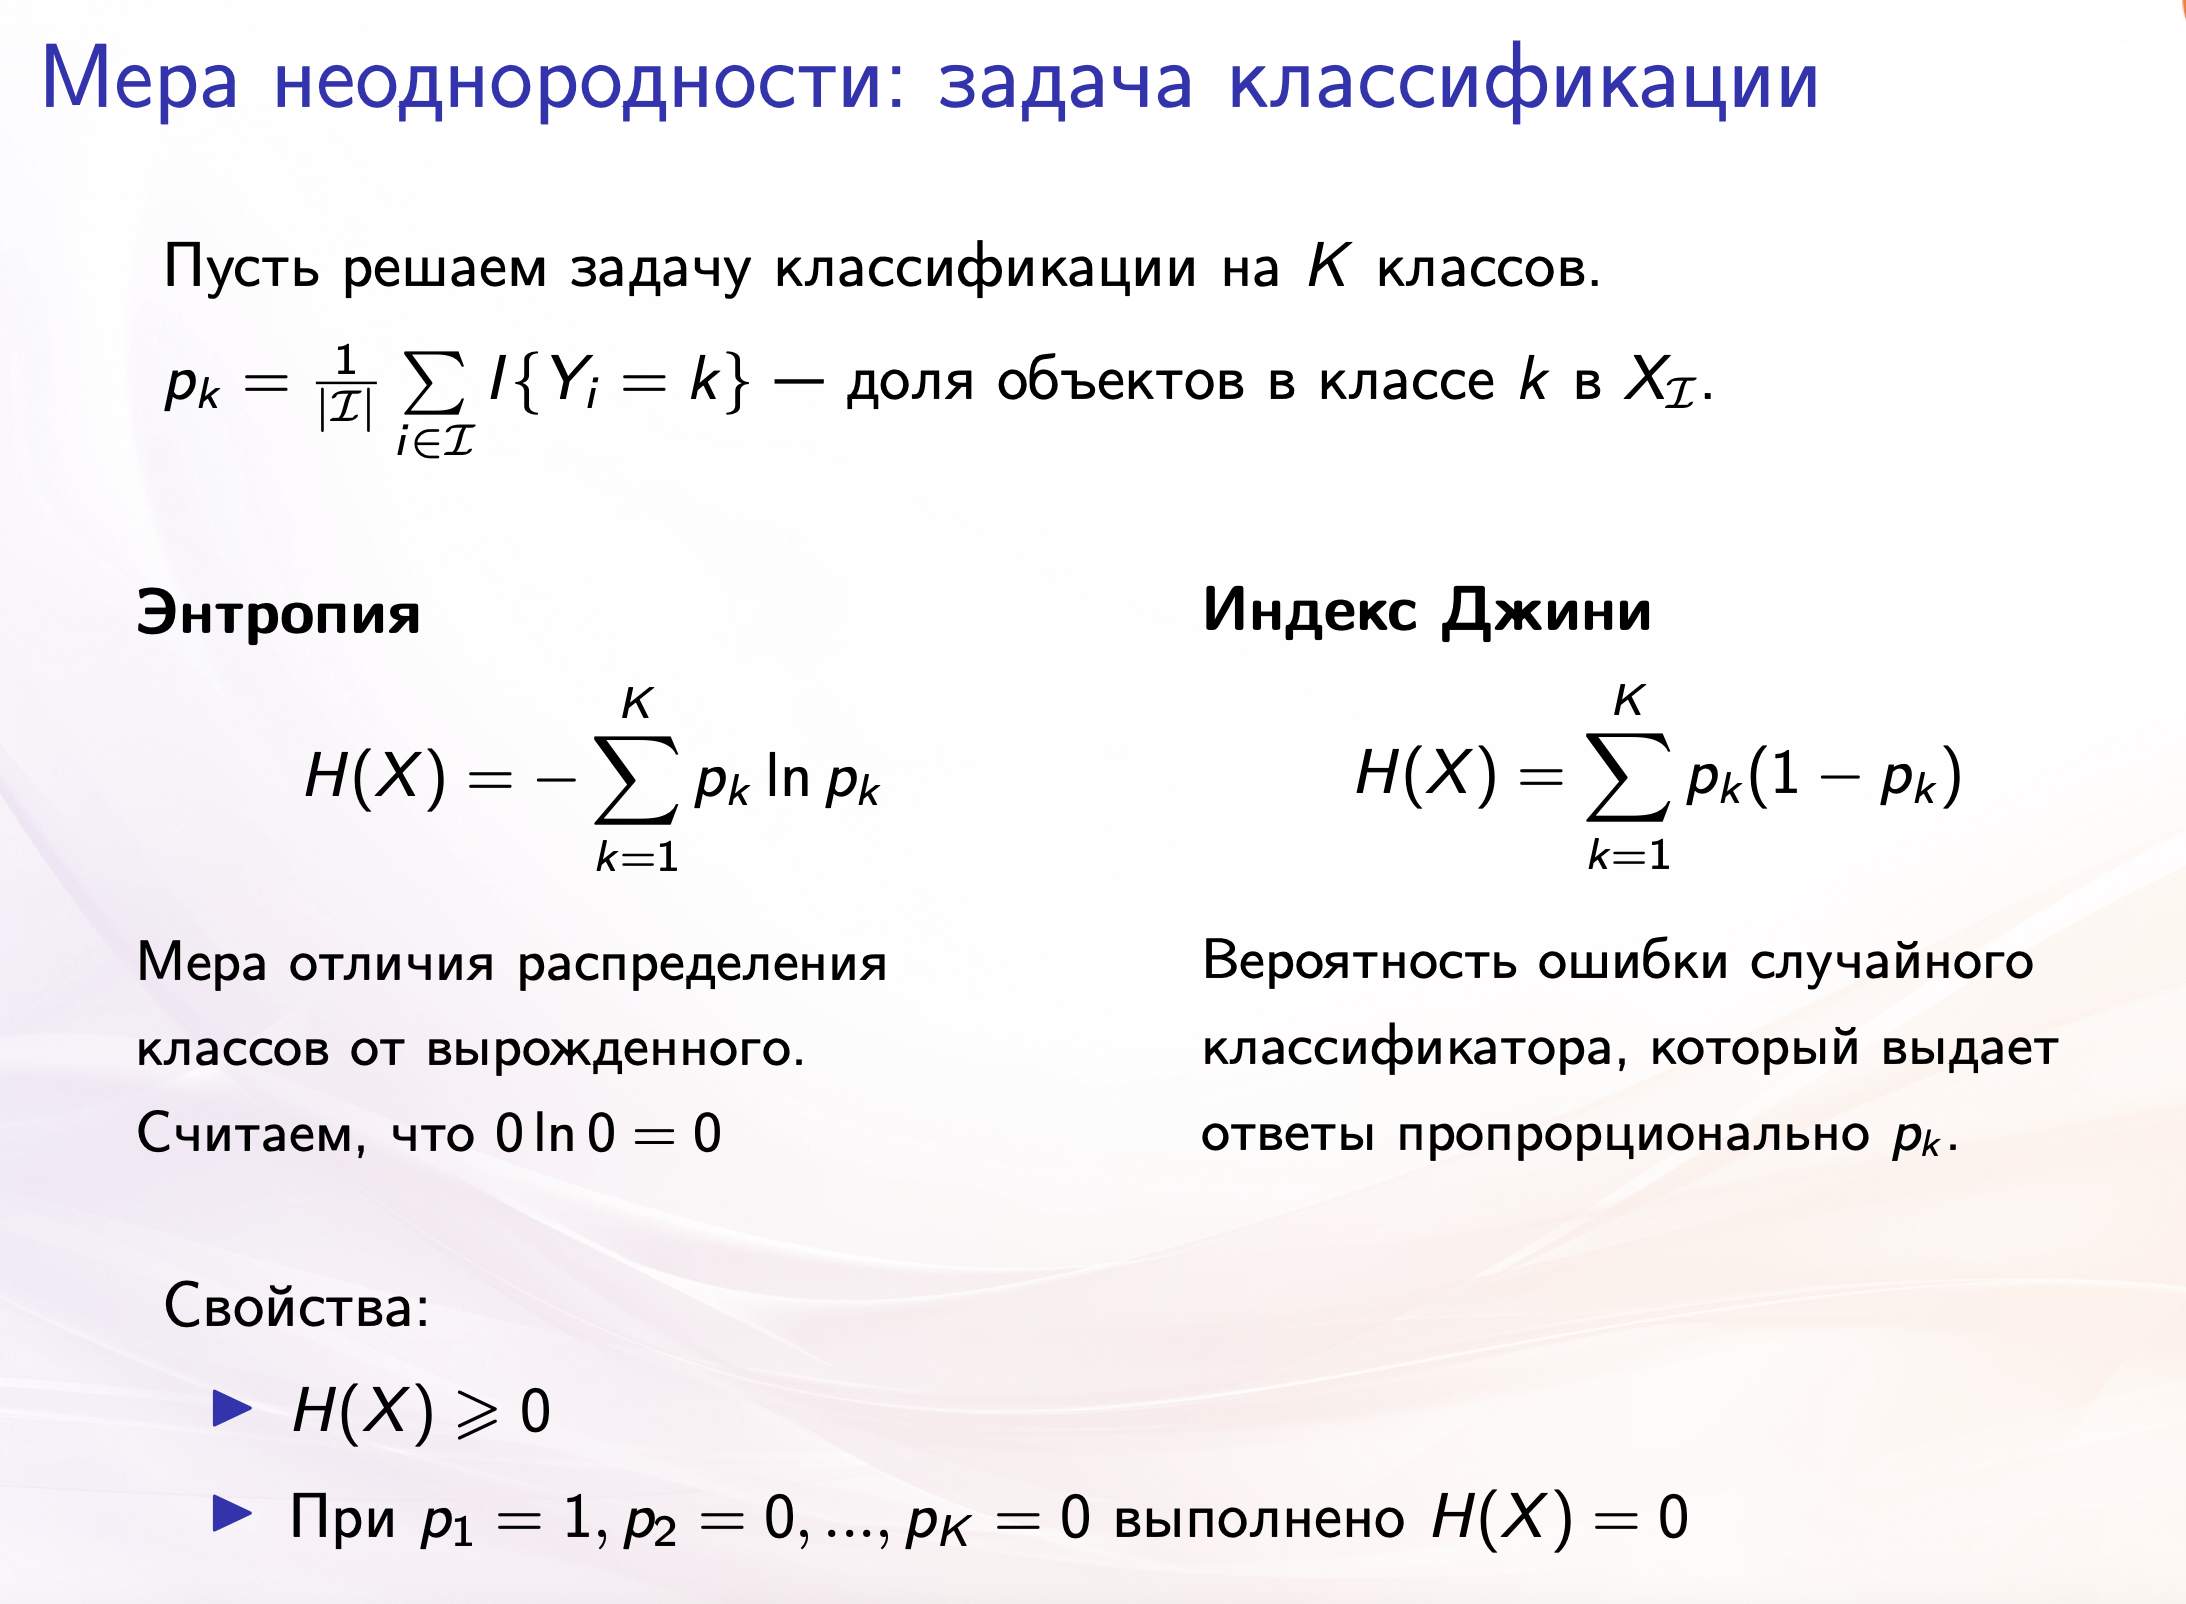


Рассматриваем: DummyClassifier(strategy='stratified')

То есть для примера если в выборке: белые шарики и черные шарики. Белых шариков 30% от всей выборки, а черных соответсвенно 70% от всей выборки. Тогда рассматриваемый классификатор будет генерировать число $\sim \mathcal{U}[0, 1]$ (как я делала в Марафоне ДЗ1 Статистики Заданиии 2 про кофейню), если оно $\leq 0.3$, то предсказываем белый цвет, иначе черный.

Тогда какова ошибка такого классификатора? Посчитаем руками:

Что значит, что классификатор ошибся? Допустим настоящий объект выборки - это белый шарик. Мы этот объект выбираем с вероятностью $p_{\text{белый}} = 0.3$. Но наш рассматриваемый классификатор выдал нам неверный ответ, предсказав, что шарик чёрный (ну или "небелый" если у нас мультиклассовая классификация), с какой вероятностью он это предсказал и как он это предсказал, он сгенерировал число $a \sim \mathcal{U}[0, 1]$, (геометрическая вероятность): с вероятностью $0.7$ верно, что $a > 0.3 \Longrightarrow$ то есть предсказание - черный шарик ("небелый" в случае многоклассовой классификации).

Итак, два события (рассмотрим многоклассовую классификацию, формализуем приведенные выше рассуждения и сделаем вывод):

событие 1: вытащить шарик цвета $k$ (объект класса $k$, но мне удобнее в терминах шариков рассуждать, сути дела это не меняет)

событие 2: классификатор сгенерировал число $a \sim \mathcal{U}[0, 1]$ и на основе значения $a$ предскзал класс объекта (цвет вытащенного шарика в событии 1), но предсказание оказалось неверным, то есть предсказан НЕ КЛАСС $k$

Важно: событие 1 и событие 2 - независимы, так как класс текущего объекта и генерация числа никак дург на друга не влияют, то есть как раз события независимы

Значит вероятность ошибки в данном случае = $\mathcal{P}(\text{событие 1}) \cdot \mathcal{P}(\text{событие 2})$, раз они независимы

Эта вероятность считается так (используем обозначения со слайда презентации с лекции выставленного в самом начале решения):

* $\mathcal{P}(\text{событие 1}) = p_k$
* $\mathcal{P}(\text{событие 2}) = \mathcal{P}(\text{предсказан НЕ КЛАСС k}) = 1 - p_k$

Значит вероятность ошибки для класса $k = \mathcal{P}(\text{событие 1}) \cdot \mathcal{P}(\text{событие 2})$, раз они независимы

Итоговая вероятность ошибки классификатора считается суммированием по каждому классу вероятностей ошибиться

$\mathcal{P}(\text{вероятность ошибки классификатора}) = \sum_{k = 1}^C p_k \cdot (1 - p_k)$, где $C$ - кол-во классов в задаче мультиклассовой классификации. Это ровно индекс Джини со слайда презентации с лекции выставленного в самом начале решения)


### Задача 2

Пусть $X = (x_1, ..., x_n)$ &mdash; выборка объектов и $Y = (Y_1, ..., Y_n)$ &mdash; соответствующие значения вещественного таргета. Мера неоднородности для набора объектов вычисляется на основе того, насколько хорошо их таргет предсказывается константой:

$$
H(X) = \min_{c \in \mathscr{Y}} \dfrac{1}{n} \sum_{i=1}^n L(Y_i, c),
$$

где $L(y, c)$ &mdash; некоторая функция потерь, $\mathscr{Y}$ &mdash; множество значений таргета. Соответственно, чтобы получить аналитическое выражение для меры однородности при конкретной функции потерь, необходимо аналитически найти оптимальное значение константы и подставить его в формулу для $H(X)$.

Выведите аналитическое выражение для меры неоднородности для следующих функций потерь:
1. $L(y, c) = (y-c)^2$;
2. $L(y, c) = |y-c|$.

Найдите также оптимальное предсказание в листьях дерева.

1. 1ый случай: $H(X) = \min_{c \in \mathscr{Y}} \dfrac{1}{n} \sum_{i=1}^n (Y_i - c)^2$

**Ищем $H(X)$:**

Надо найти по факту минимум MSE с константным предсказакнием модели. Чтобы найти минимум, как учит матан, надо взять производную по $c$ и приравнять к нулю:

Пусть $f(X, c) = \dfrac{1}{n} \sum_{i=1}^n (Y_i - c)^2$

$f'_{c}(X, c) = \dfrac{1}{n} \sum_{i = 1}^n 2 \cdot (Y_i - c) \cdot (-1) = 0 \Longleftrightarrow \sum_{i = 1}^n (Y_i) - nc = 0 \Longleftrightarrow \sum_{i = 1}^n (Y_i) = nc \Longleftrightarrow \frac{\sum_{i = 1}^n (Y_i)}{n} = c$, то есть $c^{*} = \frac{\sum_{i = 1}^n (Y_i)}{n}$ - точка миниммума это просто среднее арифметическое таргетов -- предсказания в листьях должно быть среднее, чтобы минимизировать меру неоднородности

чтобы получить аналитическое выражение для меры однородности при конкретной функции потерь, необходимо аналитически найти оптимальное значение константы и подставить его в формулу для $H(X)$:

$H(X) = \dfrac{1}{n} \sum_{i=1}^n (Y_i - \frac{\sum_{i = 1}^n (Y_i)}{n})^2 = \dfrac{1}{n} \sum_{i=1}^n (Y_i - \overline{Y})^2 $

**Ищем оптимальные предсказания в листьях, так чтобы минимизировать этот функционал в листе:** это просто среднее значение таргета в листе (так как таргет вещественный) = $\overline(Y)$

В листе мы решаем задачу минимизации, то есть нам нужно минимизировать меру неоднородности в листе, ведь наша цель добиться того, чтобы в каждом листе решающего дерева в конечном итоге мера неоднородности = 0.

Значит надо подставлять $\hat{y} = \frac{1}{|\mathcal{I_{\text{leaf}}}|} \sum_{i \in \mathcal{I_{\text{leaf}}}} Y_i}$

2. 2ой случай: $H(X) = \min_{c \in \mathscr{Y}} \dfrac{1}{n} \sum_{i=1}^n |Y_i - c|$

**Ищем $H(X)$:**

Это кусочно линейная функция, которая, конечно, недиффиренцируема в нуле, там где $Y_i = c$. Но доопределить то в нуле нулем можно производную. Надо найти по факту минимум MAE с константным предсказакнием модели. Чтобы найти минимум, как учит матан, надо взять производную по $c$ и приравнять к нулю:

Пусть $f(X, c) = \dfrac{1}{n} \sum_{i=1}^n |Y_i - c|$

$\dfrac{1}{n} \sum_{i=1}^n \text{sign}(Y_i - c) \cdot (-1) = 0 \Longleftrightarrow \sum_{i=1}^n \text{sign}(Y_i - c) = 0$, поскольку $\text{sign} \in \{+1, -1\}$, то эта сумма минимальна, когда:
 * в ней порувну единичек и минус единичек (если n - нечетное и $c^{*}$ центральный элемент из упорядоченного по возрастанию массива из таргетов), тут сумма = 0
 * $c^{*}$ лежит между двумя центральными элементами тогда сумма = 0 (или $c^{*}$ является одним из центральных элементов, в таком случае сума = 1 или -1)

, то есть, чтобы было так необходимо, чтобы $c$ было медианой, чтобы минимизировать меру неоднородности

$c^{*} = \text{sort}(Y_1, ..., Y_n)[\text{ceil}(n/2)]$ -- медиана -- предсказания в листьях должно быть медианой (если n четное то $c^{*}$ берется как один из двух соседних центральных элементов или лежало между двумя центральными элементами)

чтобы получить аналитическое выражение для меры однородности при конкретной функции потерь, необходимо аналитически найти оптимальное значение константы и подставить его в формулу для $H(X)$:

$H(X) = \dfrac{1}{n} \sum_{i=1}^n |Y_i - c_{\text{median}}|$

**Ищем оптимальные предсказания в листьях, так чтобы минимизировать этот функционал:** это просто медиана из всех таргетов в листе $Y_{\text{median}}$



### Задача 3

В случае задачи классификации рассматривается вероятностное предсказание, и мера неоднородности имеет вид
$$H(X) = \min_{\substack{P \in [0, 1]^K \\ p_1+...+p_K=1}} \dfrac{1}{n} \sum_{i=1}^n L\left(Y_i, P\right).$$
Выведите и упростите меру неоднородности, найдите оптимальные оценки вероятностей в листах для следующих функций потерь:
* $L(y, P) = \sum\limits_{k=1}^K \left(p_k-I\{y=k\}\right)^2$;
* $L(y, P) = -\sum\limits_{k=1}^K I\{ y=k\}\log p_k$.


$P \in [0, 1]^K = (p_1, ..., p_K)^T$

1. Первый случай:

Пусть $f(X) = \frac{1}{n} \cdot \sum_{i = 1}^n (\sum_{k = 1}^K (p_k - I\{Y_i=k\})^2)$

**Сначала выведем и упростим меру неоднорости:**

Раскрываем квадрат и рассматриваем внутреннюю сумму при фиксированном $i \in \{1, ..., n\}$, учитывая, что $ I\{Y_i = k\}^2 =  I\{Y_i = k\}$:

$\sum_{k = 1}^K (p_k - I\{Y_i=k\})^2 = \sum_{k = 1}^K (p_k^2 - 2 \cdot p_k \cdot I\{Y_i = k\} + I\{Y_i = k\})$

Теперь рассмотрим всю $f(X)$ и переставим суммы местами (так как они конечны):

$f(p) = \frac{1}{n} \cdot \sum_{i = 1}^n (\sum_{i = 1}^K (p_k^2 - 2 \cdot p_k \cdot I\{Y_i = k\} + I\{Y_i = k\})) = $

$ = \frac{1}{n} \cdot \sum_{k = 1}^K (\sum_{i = 1}^n (p_k^2 - 2 \cdot p_k \cdot I\{Y_i = k\} + I\{Y_i = k\})) =$

$= \frac{1}{n} \cdot [(\sum_{i = 1}^n (\sum_{k = 1}^K p_k^2)) - 2 \cdot \sum_{k = 1}^K (p_k \sum_{i = 1}^n I\{Y_i = k\}) + \sum_{k = 1}^K (\sum_{i = 1}^n I\{Y_i = k\})] = $

Учтем, что при фиксированном $k$ верно $\sum_{i = 1}^n I\{Y_i = k\} = |C_k|$, где $C_k$ - объекты класса $k$, тогда ясно, что $\hat{p_k} = \frac{|C_k|}{n}$ - доля обектов класса $k$ во всей выборке (частота класса $k$)

$ = \frac{1}{n} \cdot [n (\sum_{k = 1}^K p_k^2) - 2 \cdot \sum_{k = 1}^K (p_k \cdot |C_k|) + \sum_{k = 1}^K |C_k|] =$

$ = (\sum_{k = 1}^K p_k^2) - 2 \cdot \sum_{k = 1}^K p_k \cdot \hat{p_k} + \sum_{k = 1}^K \hat{p_k} = f(p)$

**В листе мы решаем задачу минимизации**, то есть нам нужно минимизировать меру неоднородности в листе, ведь наша цель добиться того, чтобы в каждом листе решающего дерева в конечном итоге мера неоднородности = 0.

Это такая задача: найти минимум функции многих переменных при заданных ограничениях - равенствах, а именно:

у нас много переменных: $p_1, ..., p_K$

так же у нас есть одно ограничение-равенство: $\sum_{k = 1}^K p_k = 1$

Для того, чтобы решить данную задачу минимизации воспользуемся методом множителей Лагранжа (из 3 семестра матанализа):

Пусть $p = (p_1, ..., p_K)^T$ - векотр предсказаных вероятностей решающего дерева. Тогда

$f(p) \to \text{min}$, при  $\sum_{k = 1}^K p_k = 1$

Запишем функцию Лагранжа и систему, к-рая поможет нам минимизировать: $L(p, \lambda) = (\sum_{k = 1}^K p_k^2) - 2 \cdot \sum_{k = 1}^K p_k \cdot \hat{p_k} + \sum_{k = 1}^K \hat{p_k} + \lambda (\sum_{k = 1}^K p_k - 1)$

Система берется из задачи поиска экстремума + равенства-ограничения

$$
\begin{cases}
  \frac{\partial L}{\partial \lambda} = \sum_{k = 1}^K p_k - 1 = 0 \\
  \forall k = 1...K:\ \frac{\partial L}{\partial p_k} = 0
\end{cases}
$$

Придерживаемся тех же обозначений, что и выше $|C_k|$ - мощность класса $k$ (кол-во объектов выборки, которые имеют таргет равный $k$, $\hat{p_k} = \frac{|C_k|}{n}$ - доля обектов класса $k$ во всей выборке (частота класса $k$))

Рассмотрим при фиксированном $k$: $\frac{\partial L}{\partial p_k} = 0 = 2p_k - 2\hat{p_k} + \lambda$

И так для любого $k \Longrightarrow p_k = \frac{|C_k|}{n} - \frac{\lambda}{2}$

Теперь найдем лямбда с помощью равенства ограничителя, подсатвляя найденные $p_k$: $\sum_{k = 1}^K p_k - 1 = 0 = \sum_{k = 1}^K (\frac{|C_k|}{n} - \frac{\lambda}{2}) - 1  = \frac{-K \lambda}{2} + \frac{n}{n} - 1 = 0$

$\Longleftrightarrow \lambda = 0$

Итак, **оптимальные оценки вероятности в листах**: $p_k = \frac{|C_k|}{n} = \hat{p_k}$, они и доставляют минимум $f(p)$
таким образом, получен **индекс Джини**: $f(p) = 1 - \sum_{k = 1}^K \hat{p_k}^2$ (если упростить последний вид $f(p)$, подставляя в него оптимальные $p_k$)



2. Второй случай:

Оговоримся, что в условии не указано основание логарифма, но мы знаем, что на минимизацию функцию константа не влияет, при перекходе от одного основания логарифма к другому появляется константа, но она не влияет на минимизацию. Значит считаем, что логарифм натуральный

Пусть $f(X) = \frac{1}{n} \cdot \sum_{i = 1}^n (-\sum_{k = 1}^K (I\{Y_i = k\} \cdot \ln p_k)) =$

**Сначала выведем и упростим меру неоднорости:**

переставим суммы местами (так как они конечны):

$= \frac{-1}{n} \cdot \sum_{k = 1}^K \ln p_k (\sum_{i = 1}^n (I\{Y_i = k\})) =$

Учтем, что при фиксированном $k$ верно $\sum_{i = 1}^n I\{Y_i = k\} = |C_k|$, где $C_k$ - объекты класса $k$, тогда ясно, что $\hat{p_k} = \frac{|C_k|}{n}$ - доля обектов класса $k$ во всей выборке (частота класса $k$)

$= \frac{-1}{n} \cdot \sum_{k = 1}^K \ln p_k \cdot |C_k| =$

$= - \sum_{k = 1}^K \hat{p_k} \cdot \ln p_k$

**В листе мы решаем задачу минимизации**, то есть нам нужно минимизировать меру неоднородности в листе, ведь наша цель добиться того, чтобы в каждом листе решающего дерева в конечном итоге мера неоднородности = 0.

Это такая задача: найти минимум функции многих переменных при заданных ограничениях - равенствах, а именно:

у нас много переменных: $p_1, ..., p_K$

так же у нас есть одно ограничение-равенство: $\sum_{k = 1}^K p_k = 1$

Для того, чтобы решить данную задачу минимизации воспользуемся методом множителей Лагранжа (из 3 семестра матанализа):

Пусть $p = (p_1, ..., p_K)^T$ - векотр предсказаных вероятностей решающего дерева. Тогда

$f(p) \to \text{min}$, при  $\sum_{k = 1}^K p_k = 1$

Запишем функцию Лагранжа и систему, к-рая поможет нам минимизировать: $L(p, \lambda) = - \sum_{k = 1}^K \hat{p_k} \cdot \ln p_k + \lambda (\sum_{k = 1}^K p_k - 1)$

Система берется из задачи поиска экстремума + равенства-ограничения

$$
\begin{cases}
  \frac{\partial L}{\partial \lambda} = \sum_{k = 1}^K p_k - 1 = 0 \\
  \forall k = 1...K:\ \frac{\partial L}{\partial p_k} = 0
\end{cases}
$$

Придерживаемся тех же обозначений, что и выше $|C_k|$ - мощность класса $k$ (кол-во объектов выборки, которые имеют таргет равный $k$, $\hat{p_k} = \frac{|C_k|}{n}$ - доля обектов класса $k$ во всей выборке (частота класса $k$))

Рассмотрим при фиксированном $k$: $\frac{\partial L}{\partial p_k} = 0 = \frac{-\hat{p_k}}{p_k} + \lambda$

И так для любого $k \Longrightarrow p_k = \frac{\hat{p_k}}{\lambda}$

Теперь найдем лямбда с помощью равенства ограничителя, подсатвляя найденные $p_k$: $\sum_{k = 1}^K p_k - 1 = 0 = \sum_{k = 1}^K (\frac{\hat{p_k}}{\lambda}) - 1  = \frac{1}{\lambda} \sum_{k = 1}^K \hat{p_k} - 1 = \frac{1}{\lambda} - 1 = 0 \Longrightarrow \lambda = 1$

Итак, **оптимальные оценки вероятности в листах**: $p_k = \frac{\hat{p_k}}{\lambda} = \hat{p_k} = \frac{|C_k|}{n}$, они и доставляют минимум $f(p)$

таким образом, получена **энтропия**: $f(p) = = - \sum_{k = 1}^K \hat{p_k} \cdot \ln \hat{p_k}$ (если упростить последний вид $f(p)$, подставляя в него оптимальные $p_k$)


### Задача 4

Каждый студент DS-потока должен написать свое дерево. Что ж, время пришло...

*Советы.*
* Для отладки кода советуем строить простые деревья глубины 1-3 на простых датасетах по 10-20 объектах, печатать обучаемые параметры и т.д.. Если все хорошо работает, в финальном решении убирайте отладочный вывод.
* Сравните качество реализованного дерева с качеством реализации из sklearn. Ровно такое же качество вы можете не получить из-за различных небольших оптимизаций, но если качество отличается на порядок, стоит проверить свою реализацию.
* Сначала лучше разобраться с одной задачей (регрессией или классификацией), а затем переходить к другой.

Ноутбук состоит из нескольких частей. Для удобства тут можно отмечать прогресс:

- [+] Реализованы меры неоднородности
- [+] Реализован `_build` в `BaseDecisionTree`
- [+] Реализован `predict_instance` для `DecisionTreeRegressor`
- [+] Реализован `predict_proba_instance` для `DecisionTreeClassifier`
- [+] Протестировано дерево на задаче регрессии для датасета `boston`
- [+] Задача классификации на датасете с пропусками

Вспомним, как именно происходит построение решающего дерева. Для построения дерева в каждой нелистовой вершине происходит разбиение подвыборки на две части по некоторому признаку $x_j$. Этот признак и порог $t$, по которому будет происходить разбиение, мы хотим брать не произвольно, а основываясь на соображениях оптимальности.  Для этого нам необходимо знать некоторый фукционал качества, который будем оптимизировать при построении разбиения.

Обозначим через $X_m$ — множество объектов, попавших в вершину $m$, разбиваемую на данном шаге, а через $X_\ell$ и $X_r$ — объекты, попадающие в левое и правое поддерево соответственно при заданном правиле $I\{x_j < t\}$. Пусть также $H$ — используемая мера неоднородности (impurity).

Выпишите функционал, который необходимо минимизировать при разбиении вершины:

**Ответ:** $Q(X_m, j, t) = \frac{|X_l|}{|X_m|} \cdot H(X_l) + \frac{|X_r|}{|X_m|} \cdot H(X_r)$

надо учитывать, что в данных могут быть пропуски, значит минимизируем следующее:

$Q(X_m, j, t) \approx \frac{|X_m \backslash X_m^o(j)|}{|X_m|} (\frac{|X_l|}{|X_m \backslash X_m^o(j)|} \cdot H(X_l) + \frac{|X_r|}{|X_m \backslash X_m^o(j)|} \cdot H(X_r))$, где $X_l$ и $X_r$ уже считаются для  $X_m^o(j)$

Итак, $Q(X_m, j, t) \approx \frac{|X_l|}{|X_m|} \cdot H(X_l) + \frac{|X_r|}{|X_m|} \cdot H(X_r)$

Короче говоря, в любом случае мы минимизируем вот эту вещь: $\frac{|X_l|}{|X_m|} \cdot H(X_l) + \frac{|X_r|}{|X_m|} \cdot H(X_r)$ при разбиении вершины

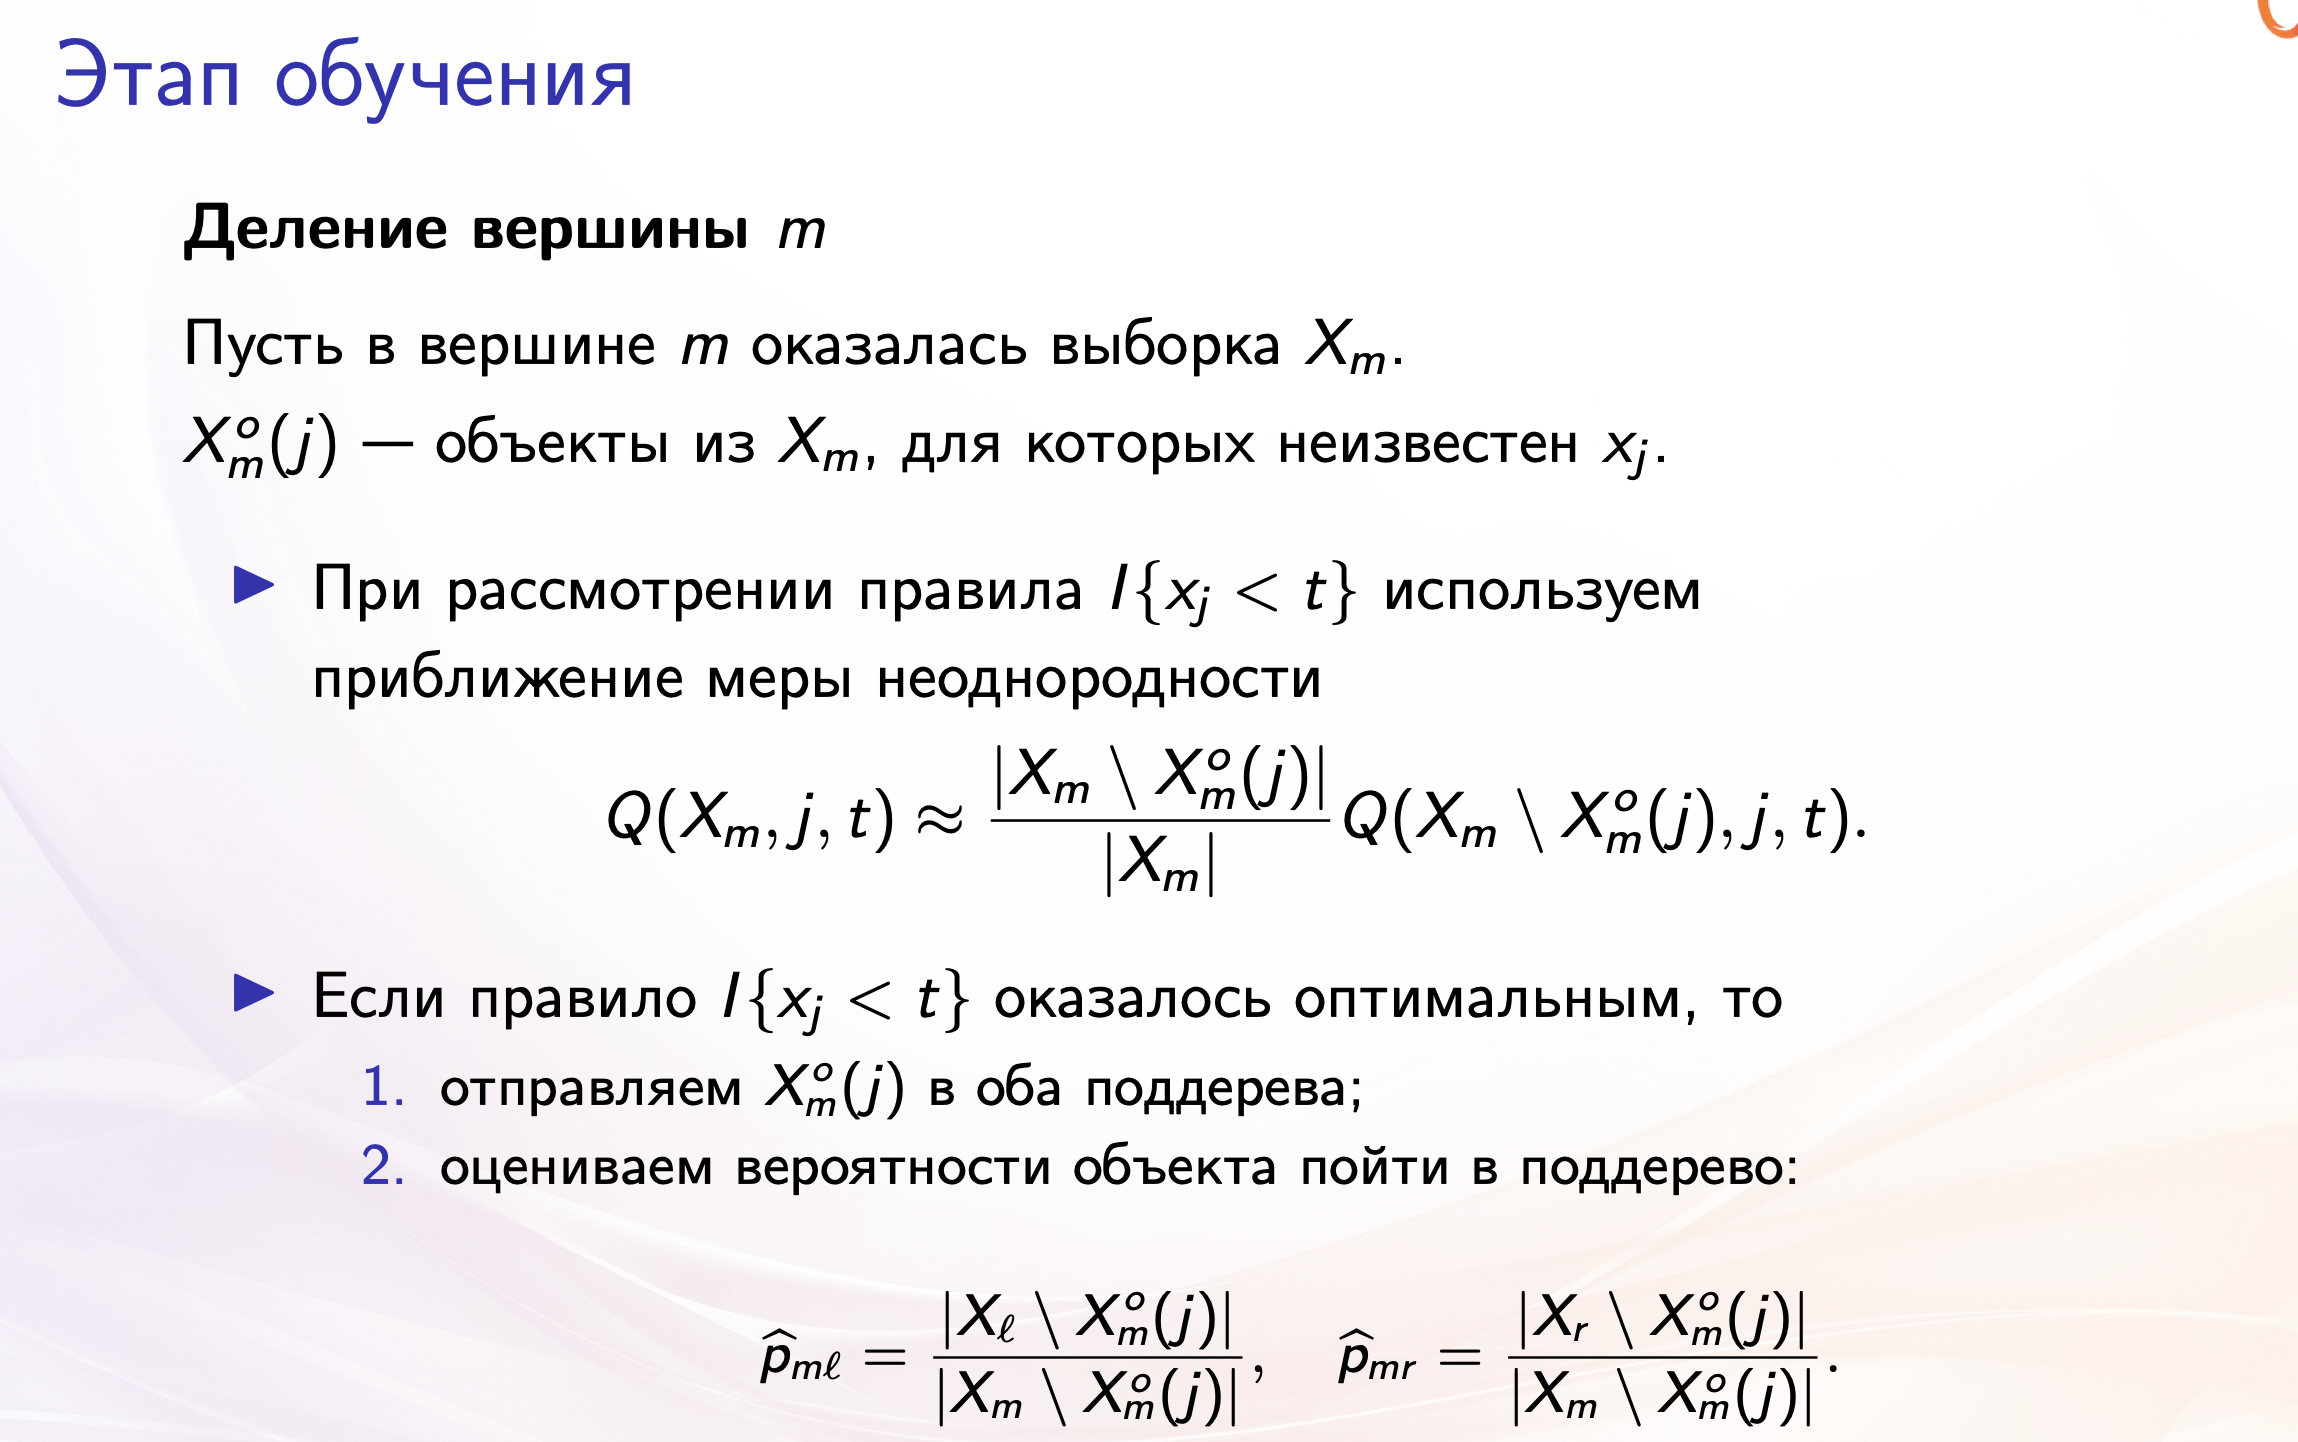

**Реализация мер неоднородности.**



Вспомните еще раз, на какой общей идее основаны меры неоднородности и какую характеристику выборки они стремятся оптимизировать?

**Ответ:** меры неоднородности основаны на идее оценки меры хаоса (неоднородности) / величины разброса в таргете в вершине. Оптимизируют однородность, пытаются ее максимизировать или что то же самое минимизировать неоднородность


Перед тем, как непосредственно работать с решающими деревьями, реализуйте функции подсчёта значения мер неоднородности вершин решающих деревьев. Использовать готовые реализации мер или классов для решающих деревьев из `sklearn` и из других библиотек **запрещено.** Также при реализации мер неоднородности по причине неэффективности **запрещается использовать циклы**. Воспользуйтесь библиотекой `numpy`.

Каждая функция принимает на вход одномерный `numpy` — массив размерности `(n,)` из значений отклика.

In [3]:
# Код функций, реализующих меры неоднородности для разбиения.

def mean_square_impurity(y: np.ndarray):
    ''' Мера по квадратичной функции потерь. '''
    y = np.array(y)
    indices_cnt = y.shape[0]
    return 1/indices_cnt * np.sum((y - np.mean(y))**2)


def mean_abs_impurity(y: np.ndarray):
    ''' Мера по абсолютной функции потерь. '''
    y = np.array(y)
    indices_cnt = y.shape[0]
    return 1/indices_cnt * np.sum(np.abs(y - np.median(y)))


def get_probs_by_y(y: np.ndarray):
    ''' Возвращает вектор частот для каждого класса выборки. '''
    y = np.array(y)
    indices_cnt = y.shape[0]
    classes, counts = np.unique(y, return_counts=True)
    return counts / indices_cnt


def gini_impurity(y: np.ndarray):
    ''' Индекс Джини. '''
    p = get_probs_by_y(y)
    return np.sum(p * (1 - p))


def entropy_impurity(y: np.ndarray):
    ''' Энтропия.'''
    p = get_probs_by_y(y)
    log_p = np.log2(p, where=(p > 0), out=np.zeros_like(p))
    return -np.sum(p * log_p)

Протестируйте реализованные функции.

Тесты для распределения вероятностей на классах.

In [4]:
assert np.allclose(get_probs_by_y([1, 1, 2, 2, 7]), np.array([0.4, 0.4, 0.2]))
assert np.allclose(get_probs_by_y([1]), np.array([1]))

Тесты для реализации мер.

In [5]:
# Для однородных данных мера должна быть 0
assert np.allclose(entropy_impurity([25]), 0)
assert np.allclose(gini_impurity([25]), 0)
assert np.allclose(mean_square_impurity([10, 10, 10]), 0)
assert np.allclose(mean_abs_impurity([10, 10, 10]), 0)

# Для равномерного распределения
assert np.allclose(gini_impurity([0, 1]), 0.5)
assert np.allclose(entropy_impurity([0, 1]), 1.0) # чтобы прошео тест надо считать довичный логарифм, а не натуральный в энтропии

**Реализация класса решающего дерева.**

Для того, чтобы лучше понять, как устроены решающие деревья и как именно устроен процесс их построения, вам предлагается реализовать класс `BaseDecisionTree`, реализующий базовые функции решающего дерева.  Большая часть кода уже написана.

Используются следующие классы:

**Класс** `BaseDecisionTree` — класс для решающего дерева, в котором реализовано построение дерева. Все вершины дерева хранятся в списке `self.nodes`, при этом вершина с номером 0 — корень.


* `__init__` — инициализация дерева. Здесь сохраняются гиперпараметры дерева: `impurity`, `max_depth`, `min_samples_split` и инициализируется список вершин, состоящий только из одной вершины — корневой,
* `build_` — рекурсивная функция построения дерева. В ней при посещении каждой вершины дерева проверяются условия, стоит ли продолжать разбивать эту вершину. Если да, то перебираются все возможные признаки и пороговые значения и выбирается та пара (признак, значение), которой соответствует наименьшее значение меры неоднородности дерева,
* `fit` — функция обучения дерева, принимающая на вход обучающую выборку. В этой функции происходит предподсчёт всех возможных пороговых значений для каждого из признаков, а затем вызывается функция `build_`.

**Класс** `Node` — класс вершины дерева. Внутри вершины, помимо разделяющего признака и порога, хранятся `self.left_child`, `self.right_child` — номера дочерних вершин, а также `self.left_prob` и `self.right_prob` — вероятности попадания элемента в каждую из них. При этом в листовых вершиных хранятся также `self.y_values` — значения соответствующих элементов выборки, попавших в вершину.

* `__init__` — инициализация вершины. Принимает в качестве аргументов разделяющий признак и пороговое значение и сохраняет их.

**Класс** `DecisionTreeRegressor` — наследник класса `BaseDecisionTree`, в котором реализованы функции для предсказаний при решении задачи регрессии.

* `predict_instance` — получение предсказания для одного элемента выборки. Выполняется посредством спуска по решающему дереву до листовой вершины,

* `predict` — получение предсказаний для всех элементов выборки.


**Класс** `DecisionTreeClassifier` — наследник класса `BaseDecisionTree`, в котором реализованы функции для предсказаний при решении задачи классификации.
* `predict_proba_instance` — предсказание распределения вероятностей по классам для одного элемента выборки,
* `predict_proba` — предсказание распределения вероятностей по классам для всех элементов выборки,
* `predict` — предсказание меток классов для всех элементов выборки.

Перед написанием кода разбиения дерева, для каждого непрерывного признака предложите стратегию выбора кандидатов на порог разбиения. Почему рассматривать другие значения в качестве пороговых не имеет смысла?

**Ответ:**

У нас есть выборка размера $n$. Отсортируем все значения непрерывного признака: $X_{j_1} \leq X_{j_2} \leq .. \leq X_{j_n}$, где $X_{j} - j$ ый признак.

Тогда в качестве $t$ - порогового значения для $X_j$ стоит рассматривать полусуммы соседей (то есть порог обязательно должен быть между соседями). А можно и не полусуммы соседей, а просто все значения np.unique(X[:, j]) взять поскольку левое поддерево имеет значения < threshold, а правое >= threshold.

Если соседние значения равны, то полусумма будет равна им же, и разделение по такому порогу смысла не имеет.

Почему рассматриваем именно такие пороги? Чтобы дерево могло четко принять решение (отделить один объект от другого).



**Структура решающего дерева**


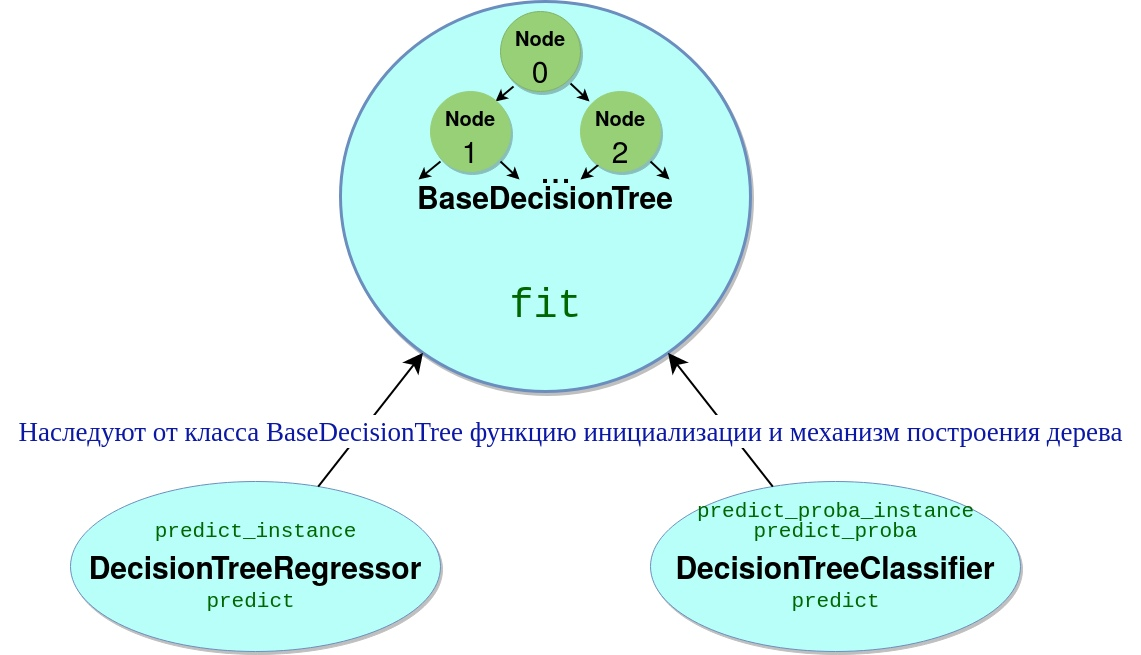

In [6]:
def get_not_nans(values: np.ndarray) -> np.ndarray:
    """Возвращает массив без NaN."""
    return values[~np.isnan(values)]

class Node(object):
    def __init__(self, split_feature: Optional[int]=None, split_threshold: Optional[float]=None):
        '''
        Функция инициализации вершины решающего дерева.

        Параметры.
        1) split_feature — номер разделяющего признака
        2) split_threshold — пороговое значение
        '''

        self.split_feature = split_feature        # номер разделяющего признака
        self.split_threshold = split_threshold    # пороговое значение

        # По умолчанию считаем, что у вершины нет дочерних вершин.
        self.left_child, self.right_child = None, None   # номера дочерних вершин

        # Вероятности попадания в каждую из дочерних вершин нужно поддерживать
        # для корректной обработки данных с пропусками
        self.left_prob, self.right_prob = 0, 0          # вероятности попадания элемента в левый лист и правый

        # Массив значений y. Определён только для листовых вершин дерева
        self.y_values = None


from sklearn.base import BaseEstimator

class BaseDecisionTree(BaseEstimator):
    '''
    Здесь содержится реализация всех основных функций для работы
    с решающим деревом.

    Наследование от класса BaseEstimator нужно для того, чтобы
    в дальнейшем данный   класс можно было использовать в
    различных функциях библиотеки sklearn, например, в функциях
    для кросс-валидации.
    '''

    def __init__(
        self,
        impurity: Callable[[np.ndarray], float],
        func_predict_in_leaf: Optional[Callable[[np.ndarray], float]]=None, max_depth: int=10, min_samples_split: int=2
    ):
        '''
        Функция инициализации решающего дерева.

        Параметры.
        1) impurity — мера неоднородности,
        2) func_predict_in_leaf - функция (np.mean / np.median) для предсказания в листе
        3) max_depth — максимальная глубина дерева,
        4) min_samples_split — минимальное количество элементов
        обучающей выборки,  которое должно попасть в вершину,
        чтобы потом происходило разбиение этой вершины.
        '''

        self.impurity = impurity
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split

        # Список всех вершин дерева. В самом начале работы алгоритма есть только одна вершина — корень.
        self.nodes = [Node()] # вершина с номером 0 — корень.

        # Количество классов. Актуально только при решении задачи классификации.
        self.class_count = 1

        # Сюда нужно будет записать все значения для каждого из признаков датасета (они будут нашими порогами).
        self.feature_values = None

        self.func_predict_in_leaf = func_predict_in_leaf

    def build_(self, node_index: int, X: np.ndarray, y: np.ndarray, node_depth: int = 0):
        '''
        Рекурсивная функция построения решающего дерева.

        Параметры.
        1) node_index — номер рассматриваемой вершины
        2) X, y — обучающая выборка, попавшая в текущую вершину
        3) node_depth — глубина вершины с номером node_index
        '''

        if node_depth == 0:
            print(f"Начало построения дерева, {len(y)} образцов")

        stop_cond = [   # стоит ли продолжать разбивать эту вершину
            node_depth == self.max_depth,    # достигли максимальной глубины
            len(y) < self.min_samples_split, # число элементов в листе мало
        ]

        if any(stop_cond):
            # Еcли строим дерево для классификации, то сохраняем метки классов всех элементов выборки, попавших в вершину.
            if callable(getattr(self, 'set_class_count', None)):
                # DecisionTreeClassifier имеет такой метод и это функция - callable
                self.nodes[node_index].y_values = y.copy()
                # Массив значений y. Определён только для листовых вершин дерева

            # Для регрессии сразу вычислим среднее всех элементов вершины.
            else:
                if y.shape[0] == 0: # чтоб warning не было, что функции np.mean = self.func_predict_in_leaf подали на вход пустой y
                    self.nodes[node_index].y_values = 0.0
                else:
                    self.nodes[node_index].y_values = self.func_predict_in_leaf(y)
            return

        best_impurity_value = np.inf
        best_feature, best_threshold = 0, 0
        sample_size, feature_count = X.shape

        # переберём все возможные признаки и значения порогов,
        # найдём оптимальный признак и значение порога
        # и запишем их в best_feature, best_threshold
        for feature_id in range(feature_count):
            not_nan_mask = ~np.isnan(X[:, feature_id])
            for threshold in self.feature_values[feature_id]:
                left_mask = (X[:, feature_id] < threshold) & not_nan_mask
                right_mask = (X[:, feature_id] >= threshold) & not_nan_mask
                # это уже в терминалогии слайдов лекции X_l \ X_l^o(j)

                y_left, y_right = y[left_mask], y[right_mask]

                if y_left.shape[0] == 0 or y_right.shape[0] == 0:
                    continue
                # пропустим пустые разбиения (чтобы не было деления на 0 в моей функции Jiny например, к-рая вызывает get_probs_by_y, а то там будет деление на кол-во |Y_left| или |Y_right| а оно ноль упс)
                Q = (y_left.shape[0] / sample_size * self.impurity(y_left)
                     + y_right.shape[0] / sample_size  * self.impurity(y_right))
                # такой подсчет даже для данных с пропусками приблизительно дает оценку на реальный Q (выше я вывела что для данных с пропусками примерно тот же Q)

                if Q < best_impurity_value:
                    best_impurity_value, best_feature, best_threshold = Q, feature_id, threshold

                    # Вероятности попадания в каждую из дочерних вершин нужно поддерживать
                    # для корректной обработки данных с пропусками
                    self.nodes[node_index].left_prob = y_left.shape[0] / np.sum(~np.isnan(X[:, best_feature]))
                    self.nodes[node_index].right_prob = y_right.shape[0] / np.sum(~np.isnan(X[:, best_feature]))

        # сохраним найденные параметры в класс текущей вершины
        self.nodes[node_index].split_feature = best_feature
        self.nodes[node_index].split_threshold = best_threshold

        # разделим выборку на 2 части по порогу
        nan_mask_best = np.isnan(X[:, best_feature])
        # | nan_mask_best - или данные с пропусками, данные с пропусками надо отправить в оба поддерева!
        left_mask = ((X[:, best_feature] < best_threshold) & ~nan_mask_best) | nan_mask_best
        right_mask = ((X[:, best_feature] >= best_threshold) & ~nan_mask_best) | nan_mask_best
        X_left, y_left, X_right, y_right = X[left_mask], y[left_mask], X[right_mask], y[right_mask]

        # создаём левую и правую дочерние вершины,
        # и кладём их в массив self.nodes
        self.nodes.append(Node())
        self.nodes.append(Node())

        # сохраняем индексы созданных вершин в качестве
        # левого и правого сына вершины node_index
        self.nodes[node_index].left_child, self.nodes[node_index].right_child =\
            len(self.nodes)-2, len(self.nodes)-1

        # рекурсивно строим дерево для дочерних вершин
        self.build_(self.nodes[node_index].left_child, X_left, y_left, node_depth+1)
        self.build_(self.nodes[node_index].right_child, X_right, y_right, node_depth+1)

    def fit(self, X: np.ndarray, y: np.ndarray):
        '''
        Функция, из которой запускается построение
        решающего дерева по обучающей выборке.

        Параметры.
        X, y — обучающая выборка
        '''

        # сохраним заранее все пороги для каждого из
        # признаков обучающей выборки
        X, y = np.array(X), np.array(y)
        self.feature_values = []
        for feature_id in range(X.shape[1]):
            self.feature_values.append(
                np.unique(get_not_nans(X[:, feature_id]))
            )

        set_class_count = getattr(self, 'set_class_count', None)

        # если строится дерево для классификации, то нужно посчитать количество классов
        if callable(set_class_count):
            set_class_count(y)

        # строим само дерево
        self.build_(0, X, y)

Теперь, когда общий код решающего дерева написан, нужно сделать обёртки над `BaseDecisionTree` — классы `DecisionTreeRegressor` и `DecisionTreeClassifier` для использования решающего дерева в задачах регрессии и классификации соответственно.

Допишите функции `predict_instance` и `predict_proba_instance` в классах для регрессии и классификации соответственно. В этих функциях нужно для одного элемента $x$ выборки промоделировать спуск в решающем дереве, а затем по листовой вершине, в которой окажется объект, посчитать для классификации — распределение вероятностей, а для регрессии — число $y$.

In [7]:
# для лучшей совместимости с sklearn я добавлю еще наследование от RegressorMixin (чтобы .score() по умолчанию была R^2)
from sklearn.base import RegressorMixin

class DecisionTreeRegressor(BaseDecisionTree, RegressorMixin):
    def predict_instance(self, x: np.ndarray, node_index: int):
        '''
        Рекурсивная функция, предсказывающая значение
        y для одного элемента x из выборки.

        Параметры.
        1) x — элемент выборки, для которого
        требуется предсказать значение y
        2) node_index — рассматриваемая вершина дерева
        '''

        # если вершина — лист, возвращаем в качестве предсказания
        # среднее всех элементов, содержащихся в ней
        if self.nodes[node_index].left_child is None:
            return self.nodes[node_index].y_values # в BaseDecisionTree.build уже вычислили среднее

        # если у объекта x значение признака по
        # которому происходит разделение,  меньше
        # порогового, то спускаемся в левое поддерево,
        # иначе — в правое
        if x[self.nodes[node_index].split_feature] < self.nodes[node_index].split_threshold:
            return self.predict_instance(x, self.nodes[node_index].left_child)
        elif x[self.nodes[node_index].split_feature] >= self.nodes[node_index].split_threshold:
            return self.predict_instance(x, self.nodes[node_index].right_child)

        # а если у элемента отсутствует значение
        # разделяющего признака,  то будем спускаться
        # в оба поддерева
        else:
            left_predict = self.predict_instance(x, self.nodes[node_index].left_child)
            right_predict = self.predict_instance(x, self.nodes[node_index].right_child)

            # Учтем вероятности пойти в левое и правое поддерево с учетом того, что в данных может быть nan (см сладйы лекции)
            return left_predict * self.nodes[node_index].left_prob + right_predict * self.nodes[node_index].right_prob
                    # УМО E(y | пошли налево) * p(пойти налево) + .. (см слайды лекции)


    def predict(self, X: np.ndarray):
        '''
        Функция, предсказывающая значение
        y для всех элементов выборки X.

        Параметры.
        X — выборка, для которой требуется
        получить вектор предсказаний y
        '''

        return [self.predict_instance(x, 0) for x in X]

Для удобства реализации функции `predict_proba_instance` класса `DecisionTreeClassifier` будем считать, что все классы имеют целочисленные метки от 0 до $k-1$, где $k$ — количество классов. Если бы это условие не было выполнено, то нужно было бы сначала сделать предобработку меток классов в датасете.

In [8]:
from sklearn.base import ClassifierMixin # (чтобы .score() по умолчанию была средняя accuracy)

class DecisionTreeClassifier(BaseDecisionTree, ClassifierMixin):
    def set_class_count(self, y: np.ndarray):
        '''
        Функция, вычисляющая количество классов
        в обучающей выборке.

        Параметры.
        y — значения класса в обучающей выборке
        '''

        self.class_count = np.max(y) + 1

    def predict_proba_instance(self, x: np.ndarray, node_index: int):
        '''
        Рекурсивная функция, предсказывающая вектор
        вероятностей принадлежности  объекта x
        к классам

        Параметры.
        1) x — элемент выборки, для которого
        требуется предсказать значение y
        2) node_index — вершина дерева, в которой
        находится алгоритм
        '''

        if self.nodes[node_index].left_child is None:
            # считаем долю каждого класса и возвращаем вектор вероятностей
            y_leaf = self.nodes[node_index].y_values
            if y_leaf.shape[0] == 0:
                return np.zeros(self.class_count)
            # np.unique всегда возвращает уникальные значения в отсортированном по возрастанию, так что вектор: p_0, ..., p_K
            classes, counts = np.unique(y_leaf, return_counts=True)
            frequencies = counts / y_leaf.shape[0]

            probabilities = np.zeros(self.class_count) # self.class_count = кол-во классов
            # Заполняем нужные индексы (классы) вычисленными вероятностями
            probabilities[classes.astype(int)] = frequencies
            return probabilities

        # если у объекта x значение признака по которому
        # происходит разделение, меньше порогового,
        # то спускаемся в левое поддерево, иначе — в правое
        if x[self.nodes[node_index].split_feature] < self.nodes[node_index].split_threshold:
            return self.predict_proba_instance(x, self.nodes[node_index].left_child)
        elif x[self.nodes[node_index].split_feature] >= self.nodes[node_index].split_threshold:
            return self.predict_proba_instance(x, self.nodes[node_index].right_child)

        # а если у объекта отсутствует значение
        # разделяющего признака, то будем спускаться
        # в оба поддерева
        else:
            left_predict = self.predict_proba_instance(
                x, self.nodes[node_index].left_child)
            right_predict = self.predict_proba_instance(
                x, self.nodes[node_index].right_child)
            # С учетом того что в данных могут быть пропуски
            # self.nodes[node_index].left_prob = |X_left \ X_left^o(j)| / |X_m \ X_m^o(j)|
            return self.nodes[node_index].left_prob * left_predict + self.nodes[node_index].right_prob * right_predict
            # формула в конце лекционных слайдов была выведена эта которую мы return

    def predict_proba(self, X: np.ndarray):
        '''
        Функция, предсказывающая вектор вероятностей
        принадлежности объекта x к классам для
        каждого x из X

        Параметры.
        X — выборка, для которой требуется получить вектор предсказаний y
        '''

        return np.array([self.predict_proba_instance(x, 0) for x in X])

    def predict(self, X: np.ndarray):
        '''
        Функция, предсказывающая метку класса для
        всех элементов выборки X.

        Параметры.
        X — выборка, для которой требуется получить
        вектор предсказаний y
        '''

        return np.argmax(self.predict_proba(X), axis=1)

**Подбор параметров.**

В этой части задания вам предлагается поработать с написанным решающим деревом, применив его к задачи классификации и регрессии, и в обеих задачах подобрать оптимальные параметры для построения.

Не забывайте писать выводы.

**1. Задача регрессии.**

Теперь самое время протестировать работу написанного нами решающего дерева. В качестве датасета возьмите `energy` из семинара.

In [9]:
from ucimlrepo import fetch_ucirepo

energy = fetch_ucirepo(id=242)

energy_X = energy.data.features
energy_y = energy.data.targets

energy_y = energy_y["Y2"]  # берём только Y2 (Cooling Load)


def find_name(old_name: str):
    for _, row in energy.variables.iterrows():
        if row["name"] == old_name:
            return row.description


energy_X = energy_X.rename(columns=find_name)
energy_y.name = find_name(energy_y.name)

Сначала надо разбить выборку на train и test.

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(energy_X, energy_y,
    test_size=0.2,
    random_state=42
)

X_train = np.array(X_train)
X_test = np.array(X_test)

Далее для метрики `r2_score` посмотрите значение при использовании различных мер неоднородности. Возьмите оптимальные значения `max_depth` и `min_samples_split` из семинара

In [11]:
# max_depth — 6.
# min_samples_split = 5

impurity_names = [mean_square_impurity, mean_abs_impurity]
leafs_funcs = [np.mean, np.median]
max_depth = 6
min_samples_split = 7

for regression_impurity, leaf_func in zip(impurity_names, leafs_funcs):
    our_regressor_tree = DecisionTreeRegressor(
                            impurity=regression_impurity,
                            func_predict_in_leaf=leaf_func,
                            max_depth=max_depth, min_samples_split=min_samples_split)
    our_regressor_tree.fit(X_train, y_train)
    y_pred = our_regressor_tree.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    print(f"При мере неоднородности = {str(regression_impurity)} получается R2 Score = {r2}")

Начало построения дерева, 614 образцов
При мере неоднородности = <function mean_square_impurity at 0x1222a8460> получается R2 Score = 0.9616420358538571
Начало построения дерева, 614 образцов
При мере неоднородности = <function mean_abs_impurity at 0x1222a8300> получается R2 Score = 0.9269666314319757


Лучшей оказалась MeanSquareImpurity, при оптимальном значении max_depth с семинара и вручную просмотренных значения min_samples_split. Так что дальше используем ее

Постройте графики зависимости `r2-score` от максимальной глубины дерева на обучающей и тестовой выборке для каждой меры на train и на test. В качестве максимальной глубины используйте значения от 1 до 14. Значение `min_samples_split` фиксируйте.

*Совет.*
Можете использовать функции с семинара

Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева,

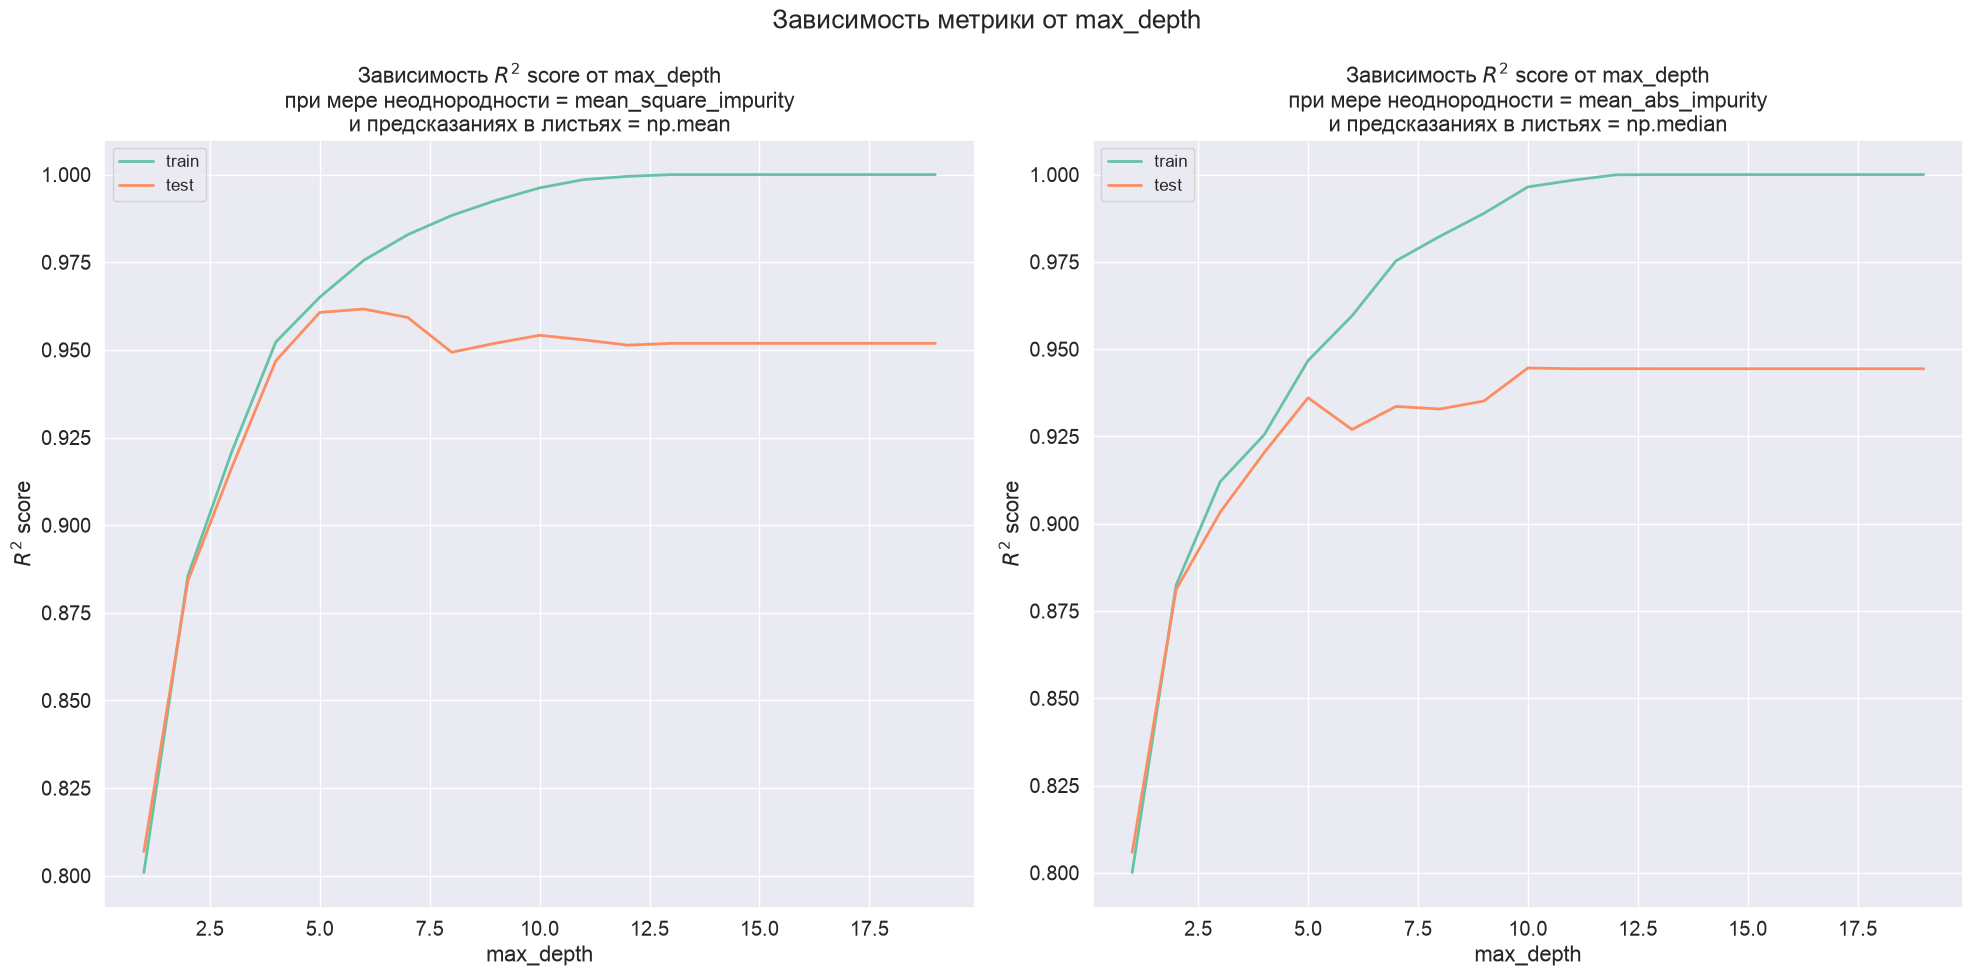

In [12]:
def get_train_and_test_regression_scores(
    param_name: str,
    grid: np.ndarray,
    impurity,
    func_predict_in_leaf
):
    '''
    Функция для оценки качества регрессии
    для заданных значений параметра param_name

    Параметры:
    param_name (str) - название параметра, который собираемся варьировать,
    grid (np.ndarray) - сетка значений параметра
    '''

    train_metrics, test_metrics = [], []

    for param_value in grid:
        estimator = DecisionTreeRegressor(**{param_name: param_value},
                                          impurity=impurity,
                                          func_predict_in_leaf=func_predict_in_leaf)
        estimator.fit(X_train, y_train)
        train_metrics.append([r2_score(y_train, estimator.predict(X_train))])
        test_metrics.append([r2_score(y_test, estimator.predict(X_test))])
    return np.array(train_metrics), np.array(test_metrics)


from typing import Tuple

def plot_dependence(
    param_name: str,
    grid: np.ndarray = range(2, 20),
    title: str = '',
    score: Callable[[str, np.ndarray], Tuple[np.ndarray, np.ndarray]]=get_train_and_test_regression_scores
  ):
    '''
    Функция для отображения графика зависимости r2 и mse
    от значения параметра с названием param_name

    Параметры:
    param_name (str) - название параметра, который собираемся варьировать.
    grid (np.ndarray) - сетка значений параметра.
    title (str) - заголовок графика.
    score (Callable) - функция вычисляющая качество модели на сетке grid.
    '''

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 10))

    # mean_square_impurity
    train_metrics, test_metrics = score(param_name, grid, impurity=mean_square_impurity, func_predict_in_leaf=np.mean)

    axes[0].plot(grid, train_metrics, label='train', lw=2)
    axes[0].plot(grid, test_metrics, label='test', lw=2)
    axes[0].set_xlabel(param_name)
    axes[0].set_ylabel('$R^2$ score')
    axes[0].legend(fontsize=12)
    axes[0].set_title(f'Зависимость $R^2$ score от {param_name}\n'
                      f'при мере неоднородности = mean_square_impurity\n'
                      f'и предсказаниях в листьях = np.mean')

    # mean_abs_impurity
    train_metrics2, test_metrics2 = score(param_name, grid, impurity=mean_abs_impurity, func_predict_in_leaf=np.median)

    axes[1].plot(grid, train_metrics2, label='train', lw=2)
    axes[1].plot(grid, test_metrics2, label='test', lw=2)
    axes[1].set_xlabel(param_name)
    axes[1].set_ylabel('$R^2$ score')
    axes[1].legend(fontsize=12)
    axes[1].set_title(f'Зависимость $R^2$ score от {param_name}\n'
                      f'при мере неоднородности = mean_abs_impurity\n'
                      f'и предсказаниях в листьях = np.median')

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_dependence(
    'max_depth', range(1, 20),
    title='Зависимость метрики от max_depth'
)

Аналогично постройте график зависимости от минимального числа элементов в вершине для разбиения ее на две части

Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева, 614 образцов
Начало построения дерева,

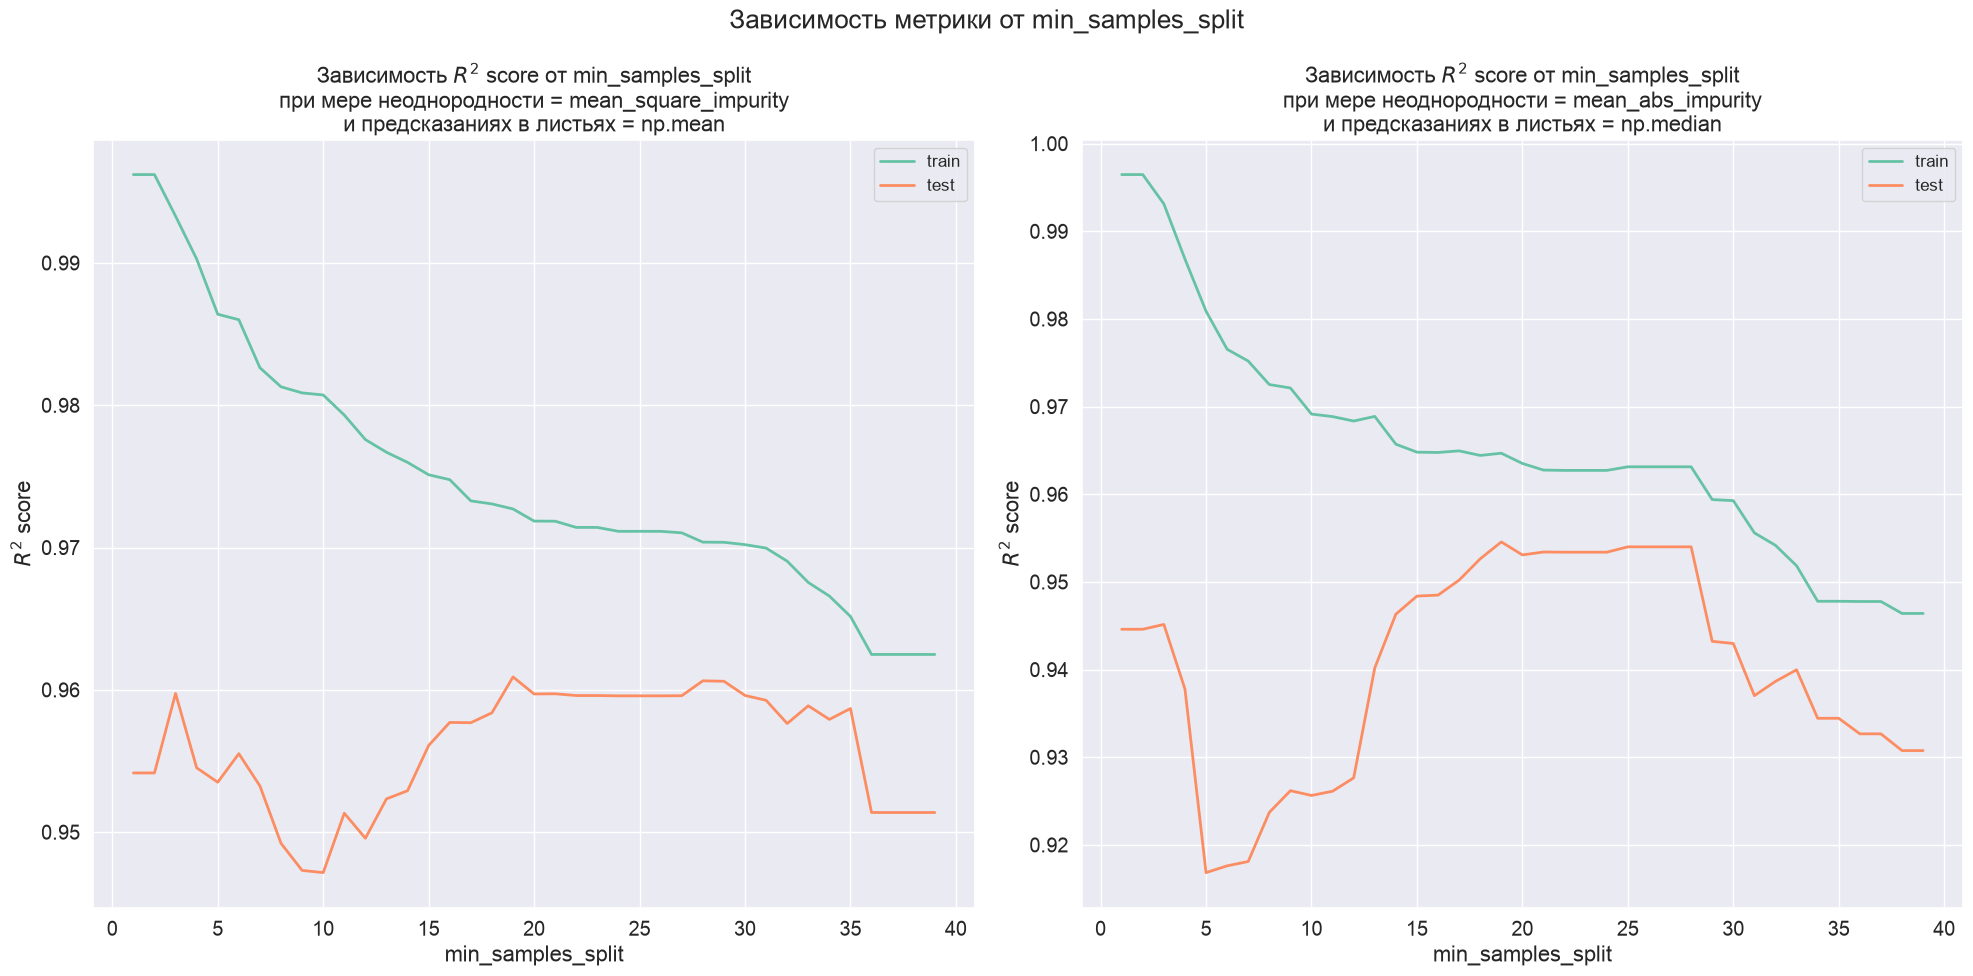

In [13]:
plot_dependence(
    'min_samples_split', range(1, 40),
    title='Зависимость метрики от min_samples_split'
)

Сделайте вывод, в котором объясните, почему графики получились такими.

Скорее всего, вы заметили, что дерево в этих экспериментах строится довольно медленно. Как можно ускорить его построение? Можно ли ускорить нахождение оптимального разбиения по некоторому вещественному признаку?

**Вывод.**

**max_depth** - максимальная глубина дерева.

Чем больше глубина дерева, тем больше в нем вершин. Чем больше в нем вершин, тем больше делений по признакам и threshold'ам, а значит тем сильнее переробучение.

* MSE с предсказанием в листях np.mean и MAE с предсказание в листьях - медиана почти не отличаются с точки зрения оптимального знначения гиперпараметра:

На верхних двух графика графике, можно видеть, что при фиксированном min_samples_split, граифк растет, то есть R2 увеличивается на обучающей выборке (переобучение под обучающую выборку), но на тесте выходит на довольно неплохое плато. Действительно по графику видно, что оптимальное значение max_depth = 5 для обеих мер неоднородности

**min_samples_split** - минимальное кол-во объектов, к-рое должнло лежать в вершине, для того, чтобы вершину можно было раздвоить на два дочерних узла.

При маленьких min_samples_split дерево может дробить вершину чуть ли чтобы в листьях ни по одному элементу было. Это переобучение, поэтому значение метрики высокое. При больших min_samples_split эффект переобучения снижается, поскольку дерево останавливает раздвоение вершин раньше, из-за этого предсказания в листах считаются по бОльшему набору данных и конечно могут быть менее точны.

* MSE с предсказанием в листях np.mean и MAE с предсказание в листьях - медиана почти не отличаются с точки зрения оптимального знначения гиперпараметра:

Видно, что левый график убывает, а правый ведет себя немного по-другому. Почему так себя ведут: из-за описаной выше концепции зависимость переобучения от min_samples_split

* При обоих мерах неоднородности оптимальное значение min_samples_split = 26

**Нет, я не заметила, что дерево в этих экспериментах строится медленно.**

Я писала об этом выше в этой же задаче, как ускорить нахождение оптимального разбиения для вещественного значения признака. А именно чтобы ускорить построение дерева можно хотя бы не перебирать все уникальные значения признака, а остортировать значения признака и смотреть только на среднее между соседями (если значение признака у соседей разное). Также, сейчас в методе build при выборе оптимального признака и порого для него мера хаоса (impurity) каждый раз считается заново от y_left, например. А можно было бы один раз отсортировать значения признака в текущей вершине и по одному добавлять / вычитать их в левую / правую дочерню вершину с помощью кумулятивных сумм, то есть пересчитывать, а не каждый раз считать заново. Чтобы еще ускорить можно бы добавить min_samples_leaf оптимальный, чтобы дерево имело еще более понятную / прозрачную структуру.

**2. Задача классификации, работа с пропусками**

В этом пункте вам предстоит освоиться с обработкой пропусков в решающих деревьях, реализованной ранее.

Рассмотрим датасет, в котором часть данных пропущена. В качестве примера возьмём <a href="https://www.openml.org/search?type=data&status=active&id=40536">датасет</a> для определения подходят ли люди друг другу по таким признакам как возраст, хобби, оценке важности некоторых свойств партнёра и другим

Поскольку предсказание в дереве на данных с пропусками часто занимает сильно больше времени, чем в случае отсутствия пропусков (так как часто приходится спускаться разу в 2 поддерева), то для экономии времени сократим датасет, взяв из него только первые 10000 строк данных.

In [14]:
dating_df = pd.read_csv("speeddating.csv")[:10000]
target = dating_df["match"]
dating_df = dating_df.drop(
    ["has_null", "match", "decision", "decision_o", "met"], axis=1
)
dating_df.head()

,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,importance_same_race,...,expected_happy_with_sd_people,expected_num_interested_in_me,expected_num_matches,d_expected_happy_with_sd_people,d_expected_num_interested_in_me,d_expected_num_matches,like,guess_prob_liked,d_like,d_guess_prob_liked
0,1.0,female,21.0,27.0,6.0,[4-6],Asian/Pacific Islander/Asian-American,European/Caucasian-American,0,2.0,...,3.0,2.0,4.0,[0-4],[0-3],[3-5],7.0,6.0,[6-8],[5-6]
1,1.0,female,21.0,22.0,1.0,[0-1],Asian/Pacific Islander/Asian-American,European/Caucasian-American,0,2.0,...,3.0,2.0,4.0,[0-4],[0-3],[3-5],7.0,5.0,[6-8],[5-6]
2,1.0,female,21.0,22.0,1.0,[0-1],Asian/Pacific Islander/Asian-American,Asian/Pacific Islander/Asian-American,1,2.0,...,3.0,2.0,4.0,[0-4],[0-3],[3-5],7.0,NaN,[6-8],[0-4]
3,1.0,female,21.0,23.0,2.0,[2-3],Asian/Pacific Islander/Asian-American,European/Caucasian-American,0,2.0,...,3.0,2.0,4.0,[0-4],[0-3],[3-5],7.0,6.0,[6-8],[5-6]
4,1.0,female,21.0,24.0,3.0,[2-3],Asian/Pacific Islander/Asian-American,Latino/Hispanic American,0,2.0,...,3.0,2.0,4.0,[0-4],[0-3],[3-5],6.0,6.0,[6-8],[5-6]


Предобработаем датасет, заменив категориальные признаки one-hot векторами.

In [15]:
dating_df = pd.get_dummies(dating_df, drop_first=True, dtype=int)
dating_df.head()

,wave,age,age_o,d_age,samerace,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,...,d_expected_happy_with_sd_people_[5-6],d_expected_happy_with_sd_people_[7-10],d_expected_num_interested_in_me_[10-20],d_expected_num_interested_in_me_[4-9],d_expected_num_matches_[3-5],d_expected_num_matches_[5-18],d_like_[6-8],d_like_[9-10],d_guess_prob_liked_[5-6],d_guess_prob_liked_[7-10]
0,1.0,21.0,27.0,6.0,0,2.0,4.0,35.0,20.0,20.0,...,0,0,0,0,1,0,1,0,1,0
1,1.0,21.0,22.0,1.0,0,2.0,4.0,60.0,0.0,0.0,...,0,0,0,0,1,0,1,0,1,0
2,1.0,21.0,22.0,1.0,1,2.0,4.0,19.0,18.0,19.0,...,0,0,0,0,1,0,1,0,0,0
3,1.0,21.0,23.0,2.0,0,2.0,4.0,30.0,5.0,15.0,...,0,0,0,0,1,0,1,0,1,0
4,1.0,21.0,24.0,3.0,0,2.0,4.0,30.0,10.0,20.0,...,0,0,0,0,1,0,1,0,1,0


Посмотрим на распределение пропущенных значений по признакам.

In [16]:
np.sum(dating_df.isnull(), axis=0)

wave                               0
age                               95
age_o                            104
d_age                              0
samerace                           0
                                ... 
d_expected_num_matches_[5-18]      0
d_like_[6-8]                       0
d_like_[9-10]                      0
d_guess_prob_liked_[5-6]           0
d_guess_prob_liked_[7-10]          0
Length: 440, dtype: int64

Разобьём данные на обучающую и тестовую выборки в отношении 3:1.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    dating_df.values, target.values, random_state=777, test_size=0.25 # чтоб 3 к 1 было
)

Посчитайте `accuracy` для каждой из мер неоднородности для разбиения деревьев для классификации при фиксации `max_depth`$ = 5$ `min_samples_split`$ = 3$.

In [18]:
impurity_names = [entropy_impurity, gini_impurity]

for classifier_impurity in impurity_names:
    our_classifier_tree = DecisionTreeClassifier(
                            impurity=classifier_impurity,
                            max_depth=5, min_samples_split=3)
    our_classifier_tree.fit(X_train, y_train)
    y_pred = our_classifier_tree.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"При мере неоднородности = {str(classifier_impurity)} получается accuracy = {accuracy}")

Начало построения дерева, 6283 образцов
При мере неоднородности = <function entropy_impurity at 0x1222a8930> получается accuracy = 0.8348448687350836
Начало построения дерева, 6283 образцов
При мере неоднородности = <function gini_impurity at 0x1222a87d0> получается accuracy = 0.8348448687350836


Постройте графики зависимости `accuracy` от максимальной глубины дерева и минимального числа элементов в вершине для разбиения ее на две части на обучающей и тестовой выборке, аналогично тому как сделали в пунтке с регресиией для `r2-score`.

In [ ]:
def get_train_and_test_regression_scores(
    param_name: str,
    grid: np.ndarray,
    impurity
):
    '''
    Функция для оценки качества регрессии
    для заданных значений параметра param_name

    Параметры:
    param_name (str) - название параметра, который собираемся варьировать,
    grid (np.ndarray) - сетка значений параметра
    '''

    train_metrics, test_metrics = [], []

    for param_value in grid:
        estimator = DecisionTreeClassifier(**{param_name: param_value},
                                          impurity=impurity)
        estimator.fit(X_train, y_train)
        train_metrics.append([accuracy_score(y_train, estimator.predict(X_train))])
        test_metrics.append([accuracy_score(y_test, estimator.predict(X_test))])
    return np.array(train_metrics), np.array(test_metrics)


from typing import Tuple

def plot_dependence(
    param_name: str,
    grid: np.ndarray = range(2, 20),
    title: str = '',
    score: Callable[[str, np.ndarray], Tuple[np.ndarray, np.ndarray]]=get_train_and_test_regression_scores
  ):
    '''
    Функция для отображения графика зависимости r2 и mse
    от значения параметра с названием param_name

    Параметры:
    param_name (str) - название параметра, который собираемся варьировать.
    grid (np.ndarray) - сетка значений параметра.
    title (str) - заголовок графика.
    score (Callable) - функция вычисляющая качество модели на сетке grid.
    '''

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 10))

    # entropy_impurity
    train_metrics, test_metrics = score(param_name, grid, impurity=entropy_impurity)

    axes[0].plot(grid, train_metrics, label='train', lw=2)
    axes[0].plot(grid, test_metrics, label='test', lw=2)
    axes[0].set_xlabel(param_name)
    axes[0].set_ylabel('accuracy score')
    axes[0].legend(fontsize=12)
    axes[0].set_title(f'Зависимость accuracy score от {param_name}\n'
                      f'при мере неоднородности = entropy_impurity')

    # gini_impurity
    train_metrics2, test_metrics2 = score(param_name, grid, impurity=gini_impurity)

    axes[1].plot(grid, train_metrics2, label='train', lw=2)
    axes[1].plot(grid, test_metrics2, label='test', lw=2)
    axes[1].set_xlabel(param_name)
    axes[1].set_ylabel('accuracy score')
    axes[1].legend(fontsize=12)
    axes[1].set_title(f'Зависимость accuracy score от {param_name}\n'
                      f'при мере неоднородности = gini_impurity')

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_dependence(
    'max_depth', range(1, 15),
    title='Зависимость метрики от max_depth'
)
plot_dependence(
    'min_samples_split', range(1, 15, 2),
    title='Зависимость метрики от min_samples_split'
)

Начало построения дерева, 6283 образцов
Начало построения дерева, 6283 образцов
Начало построения дерева, 6283 образцов
Начало построения дерева, 6283 образцов
Начало построения дерева, 6283 образцов
Начало построения дерева, 6283 образцов
Начало построения дерева, 6283 образцов
Начало построения дерева, 6283 образцов
Начало построения дерева, 6283 образцов
Начало построения дерева, 6283 образцов
Начало построения дерева, 6283 образцов


Сделайте выводы. Почему графики получились такими? Как соотносятся оптимальные значения параметров на обучающей и на тестовой выборках?

**Вывод.**



---
© 2026 команда <a href="https://thetahat.ru/">ThetaHat</a> для DS-потока